# 01 - Exploratory Data Analysis: who churns, and what do they do beforehand?
> **All data in this notebook is synthetic.** It was generated by `src/generate_data.py` from assumptions chosen by the author. Findings demonstrate methodology, not real-world evidence.

**Business question.** Which subscribers cancel within 30 days of the snapshot date (2025-12-31), and which observable signals precede cancellation?

**Contents:** data quality -> target balance -> structural drivers -> behavioural leading indicators -> statistical tests -> takeaways.

In [1]:
import sys, json; sys.path.insert(0, "..")
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import config as C
pd.set_option("display.max_columns", 50); pd.set_option("display.precision", 3)
FIG = C.FIGURES

## 1. Data quality: what the raw files looked like
The generator deliberately injects realistic problems (duplicates, inconsistent labels, impossible ages, missing values). `src/clean.py` fixes each one and logs counts.

In [2]:
raw = pd.read_csv(C.DATA_RAW / 'customers.csv')
print('raw rows:', len(raw), '| unique ids:', raw.customer_id.nunique())
print('contract_type variants:', sorted(raw.contract_type.unique()))
print('age range:', raw.age.min(), '->', raw.age.max())
print(raw.isna().mean().round(4)[lambda s: s > 0].to_string())
print(json.dumps(json.load(open(C.REPORTS / 'cleaning_report.json')), indent=2))

raw rows: 50150 | unique ids: 50000
contract_type variants: ['MONTH-TO-MONTH', 'Month to month', 'Month-to-month', 'ONE YEAR', 'One year', 'TWO YEAR', 'Two year', 'month-to-month', 'one year', 'two year']
age range: -1.0 -> 999.0
age               0.029
monthly_charge    0.005
payment_method    0.009
{
  "rows_in": 50150,
  "duplicate_rows_removed": 150,
  "contract_labels_standardised": 399,
  "impossible_ages_set_to_nan": 163,
  "age_missing_total": 1616,
  "monthly_charge_recovered_from_billing": 257,
  "payment_method_missing_to_unknown": 466,
  "rows_out": 50000,
  "billing_rows": 300000,
  "ticket_rows": 56045,
  "label_rows": 50000
}


**Reading this.** 150 duplicate customer rows, 382 inconsistent contract labels and 160 impossible ages were found. Missing `monthly_charge` was recovered from billing history rather than dropped. Impossible ages were set to missing and are imputed *inside* the modelling pipeline (fit on training folds only) to avoid leakage.

## 2. Target balance

In [3]:
mt = pd.read_csv(C.DATA_PROCESSED / 'model_table.csv')
print(mt[C.TARGET].value_counts())
print(f"churn rate = {mt[C.TARGET].mean():.2%}")

churned_30d
0    46038
1     3962
Name: count, dtype: int64
churn rate = 7.92%


About 8% of customers churn, so accuracy is meaningless (predicting *nobody churns* gives 92% accuracy). We use PR-AUC, recall/precision in the top decile and lift instead.

## 3. Structural drivers

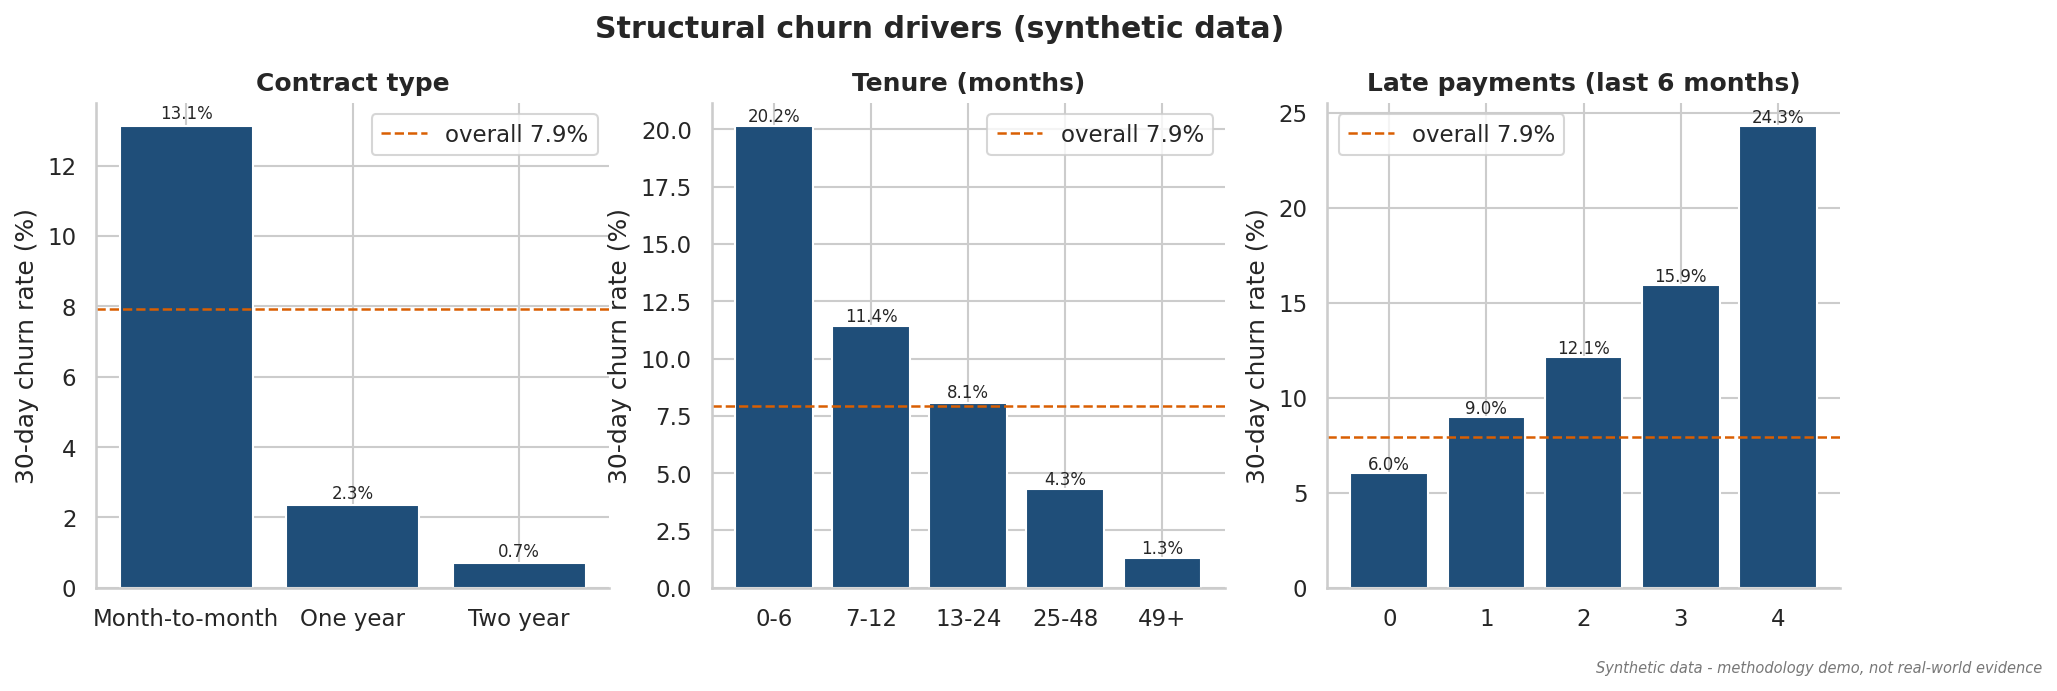

                 mean   size
contract_type               
Month-to-month  0.131  27390
One year        0.023  12668
Two year        0.007   9942


In [4]:
display(Image(FIG / 'eda_structural_drivers.png'))
print(mt.groupby('contract_type')[C.TARGET].agg(['mean','size']))

**Finding.** Month-to-month customers churn at ~13% versus ~2.3% (one-year) and ~0.7% (two-year). Churn falls steeply with tenure: roughly 20% in the first six months versus ~1% after four years. Each additional late payment raises risk. *Action:* the first six months of a month-to-month relationship is the highest-leverage window for save and upgrade offers.

## 4. Behavioural leading indicators

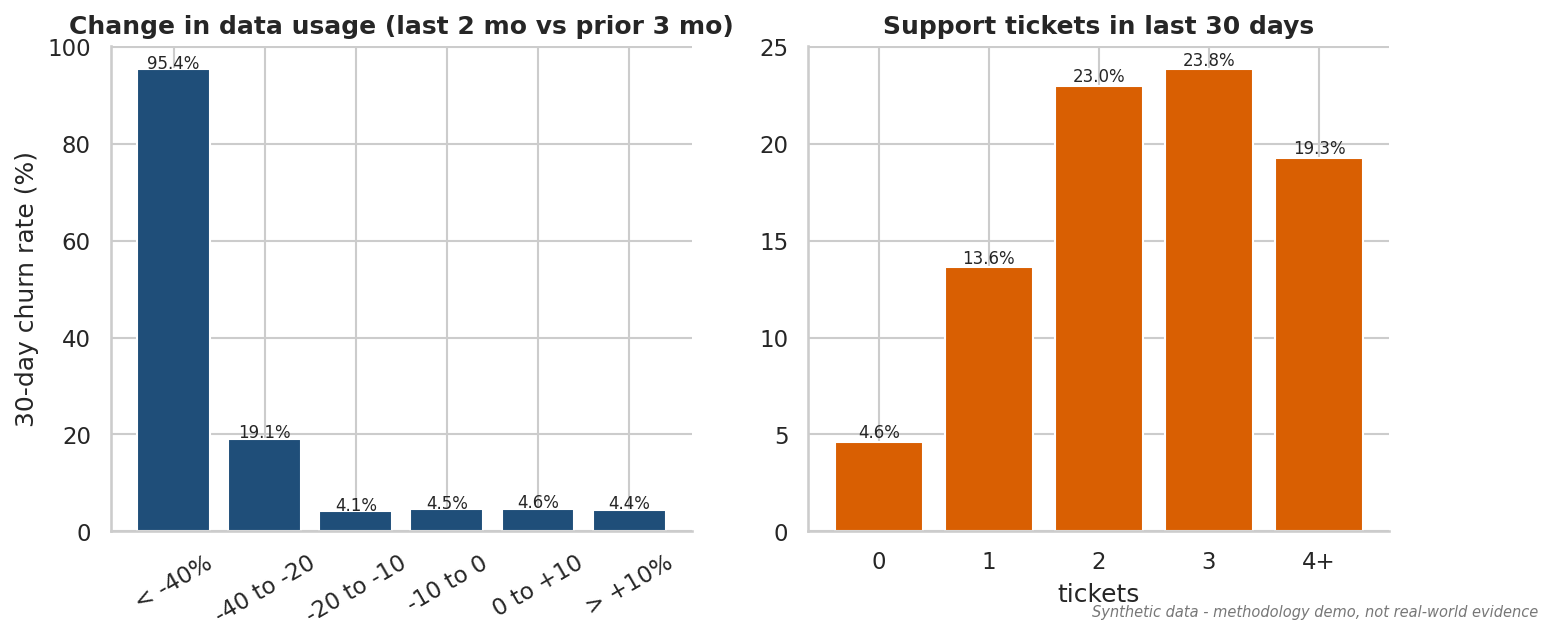

Churn rate when usage fell >20%: 0.293 | share of base: 0.14
Churn rate by tickets in last 30 days: {'0': 0.0463, '1': 0.1363, '2': 0.2299, '3': 0.2231}
Share of churners with NEITHER a usage drop NOR a ticket: 0.217


In [5]:
display(Image(FIG / 'eda_behavioural_signals.png'))
e = json.load(open(C.REPORTS / 'eda_stats.json'))
print('Churn rate when usage fell >20%:', round(e['churn_rate_usage_drop_over20pct'], 3),
      '| share of base:', round(e['share_of_customers_usage_drop_over20pct'], 3))
print('Churn rate by tickets in last 30 days:', e['churn_rate_by_tickets_30d'])
print('Share of churners with NEITHER a usage drop NOR a ticket:', round(e['churners_without_usage_drop_or_ticket_spike'], 3))

**Finding.** Customers whose data usage fell more than 20% churn at ~29% (3.7x the base rate) while representing only 14% of the base. Customers with 2+ tickets in 30 days churn at 22-23% versus ~4.6% with none. Roughly one in five churners shows *neither* signal, which is why a multivariate model beats simple rules. These effects were planted in the generator; the exercise shows that the pipeline recovers them.

## 5. Statistical tests

In [6]:
rows = []
for k, v in e.items():
    if k.startswith('mannwhitney_'):
        rows.append({'feature': k.replace('mannwhitney_', ''), **v})
print(pd.DataFrame(rows).to_string(index=False))
print('\nChi-square contract vs churn:', e['chi2_contract_vs_churn'])

             feature  median_churn  median_retained    p_value  rank_biserial
usage_change_60d_pct       -22.001           -2.704  0.000e+00          0.444
         tickets_30d         1.000            0.000  0.000e+00         -0.356
      monthly_charge        85.125           64.000 4.377e-199         -0.288
       tenure_months        10.000           24.000  0.000e+00          0.451

Chi-square contract vs churn: {'chi2': 2269.8095756106677, 'dof': 2, 'p_value': 0.0, 'cramers_v': 0.21306382027977758}


All tests are significant (p effectively 0 at n = 50,000), so **effect size matters more than p-values**: rank-biserial correlations of ~0.44-0.45 for usage change and tenure indicate large effects, and Cramer's V of 0.21 for contract type indicates a moderate association. Median monthly charge is higher among churners ($85 vs $64): price sensitivity matters.

## 6. Correlation snapshot

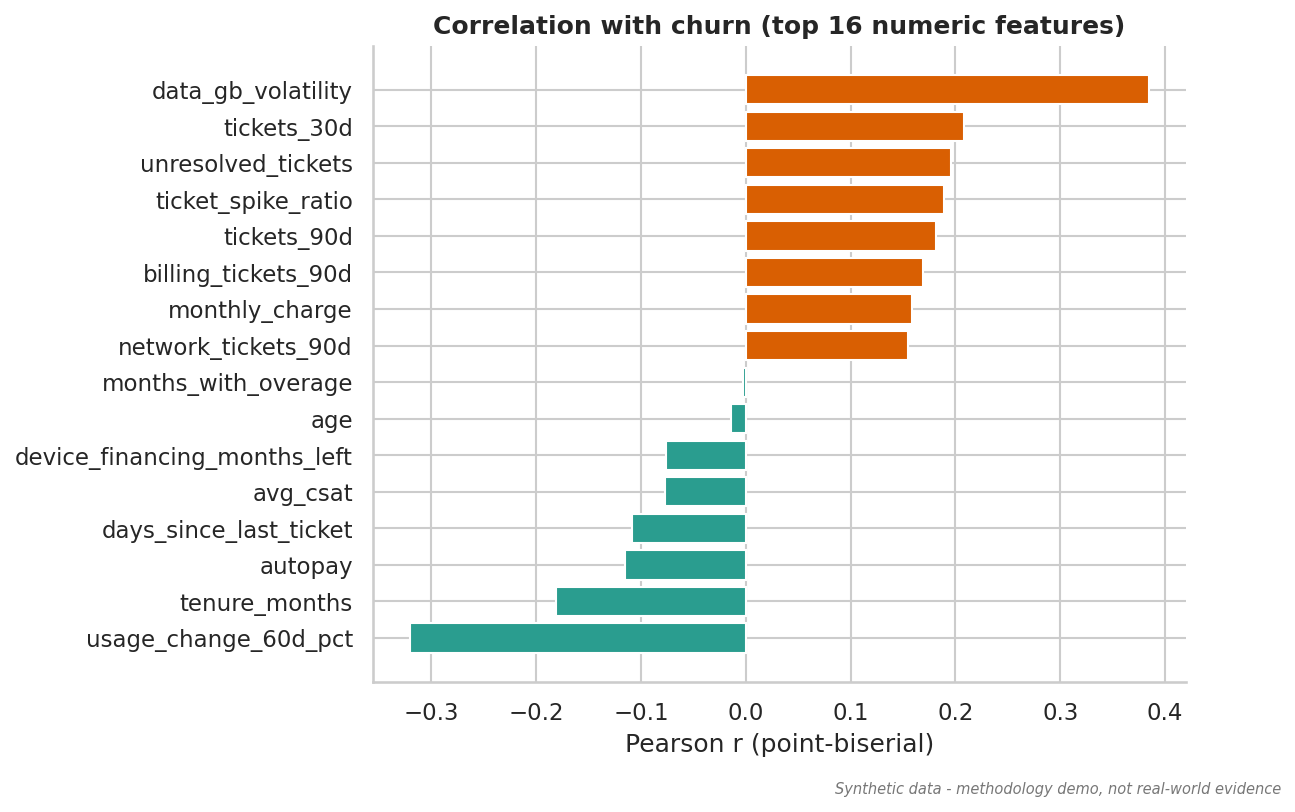

In [7]:
display(Image(FIG / 'eda_feature_correlation.png'))

## Takeaways
1. Contract type, tenure, usage trend and recent support contacts are the strongest signals.
2. Signals overlap and ~22% of churners are 'silent', so we need a multivariate model.
3. Next: `02_modeling.ipynb` compares algorithms and class-imbalance strategies.